# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model
**Scenario.** A Jinja fish-export cooperative asks (a) is our harvesting rate sustainable and (b) how risky is our revenue?
All inputs are illustrative: r = 0.4 per week, K = 10,000 t, N(0) = 4,000 t, price starts at UGX 12,000/kg bounded 9,000-16,000.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.fishery import *

pd.set_option("display.float_format", "{:,.3f}".format)
WEEKS = 52
H_RATES = [0.05, 0.10, 0.20, 0.30]
prices = PriceModel(start=12_000, sigma=350, low=9_000, high=16_000, seed=42)
risk = RiskAssessor(low=0.15, high=0.30)

## Task 1: the Fibonacci baseline (and why it fails)

In [2]:
fib = fibonacci_stock(15)
print(fib)
print("Weekly growth ratios settle at", round(fib[-1] / fib[-2], 4))
print("After 52 weeks the 'stock' would be", f"{fibonacci_stock(52)[-1]:,}", "tonnes in a lake that holds ~10,000 t")

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Weekly growth ratios settle at 1.618
After 52 weeks the 'stock' would be 32,951,280,099 tonnes in a lake that holds ~10,000 t


Fibonacci numbers grow by a factor of about 1.618 every step, i.e. +62 % per week, with no upper limit. Real fish populations are limited by food, spawning habitat and space, so growth slows as the population nears the lake's carrying capacity. The sequence also has no death rate and no fishing in it: nothing can be harvested out of it, so it can say nothing about sustainability. After 52 weeks it reaches tens of billions of tonnes, far more than the whole lake could ever hold. It is a toy sequence, not a population model.

## Task 2: `FishStock`, logistic growth with harvesting
`N(t+1) = N(t) + r N(t)(1 - N(t)/K) - h N(t)`. Growth is fast when the stock is small and zero at K; harvesting removes a fixed fraction each week.

In [3]:
stocks, harvests = {}, {}
for h in H_RATES:
    fs = FishStock(r=0.4, K=10_000, n0=4_000, h=h)
    stocks[h], harvests[h] = fs.simulate(WEEKS)
    print(f"h={h:.2f}: {fs}  status = {fs.status():12s} equilibrium N* = {fs.equilibrium():,.0f} t")

h=0.05: FishStock(r=0.4, K=10000.0, n0=4000.0, h=0.05)  status = Sustainable  equilibrium N* = 8,750 t
h=0.10: FishStock(r=0.4, K=10000.0, n0=4000.0, h=0.1)  status = Sustainable  equilibrium N* = 7,500 t
h=0.20: FishStock(r=0.4, K=10000.0, n0=4000.0, h=0.2)  status = At MSY       equilibrium N* = 5,000 t
h=0.30: FishStock(r=0.4, K=10000.0, n0=4000.0, h=0.3)  status = Overfishing  equilibrium N* = 2,500 t


## Task 3: `PriceModel` and weekly revenue
A seeded random walk (Gaussian steps, sd UGX 350/week) clipped to [9,000, 16,000]. Revenue = harvest (tonnes x 1,000 = kg) x price.

In [4]:
price = prices.path(WEEKS)
print(f"Price path: start {price[0]:,.0f}, min {price.min():,.0f}, max {price.max():,.0f}, end {price[-1]:,.0f} UGX/kg")
revenue = {h: weekly_revenue(harvests[h], price) for h in H_RATES}

Price path: start 12,000, min 10,719, max 13,812, end 13,812 UGX/kg


## Task 4: revenue statistics and why a variance threshold of 50,000 is meaningless
Variance has units of **UGX squared**. It is also scale-dependent: reporting revenue in thousands of shillings divides the variance by a million. A threshold of 50,000 UGX² corresponds to a standard deviation of only about UGX 224, which is nothing against weekly revenue in the billions, so *every* realistic series would be flagged as risky. The **coefficient of variation** (CV = std / mean) is unit-free and compares dispersion with the size of the business.

In [5]:
rows = []
for h in H_RATES:
    d = risk.describe(revenue[h])
    rows.append(dict(h=h, mean_bn=d["mean"]/1e9, median_bn=d["median"]/1e9, std_bn=d["std"]/1e9,
                     variance_UGX2=d["variance"], var_over_50000=d["variance"]/50_000, CV=d["cv"]))
stats_df = pd.DataFrame(rows).set_index("h")
pd.set_option("display.float_format", "{:,.3g}".format)
display(stats_df)
pd.set_option("display.float_format", "{:,.3f}".format)

,mean_bn,median_bn,std_bn,variance_UGX2,var_over_50000,CV
h,,,,,,
0.05,5.06,5.15,0.749,5.61e+17,1.12e+13,0.148
0.1,8.71,8.83,1.17,1.38e+18,2.76e+13,0.135
0.2,11.8,11.8,1.05,1.09e+18,2.19e+13,0.0883
0.3,9.85,9.56,1.11,1.22e+18,2.44e+13,0.112


## Task 5: `RiskAssessor`: CV rule and Monte Carlo VaR
**Rule:** CV < 0.15 is *Low* risk, 0.15-0.30 *Moderate*, above 0.30 *High*. These are the usual rule-of-thumb bands for relative dispersion (stable under about 15 %, volatile over about 30 %); they are an assumption and the thresholds are parameters of the class.
**VaR (5 %)** = expected annual revenue minus the 5th-percentile revenue: the shortfall that is exceeded in only 1 year out of 20. It comes from 2,000 simulated price paths (seeded).

In [6]:
mc, var = {}, {}
for h in H_RATES:
    mc[h] = risk.monte_carlo_annual(FishStock(h=h), prices, n_paths=2000, seed=123)
    var[h] = risk.value_at_risk(mc[h], alpha=0.05)
print("Simulated price paths:", len(mc[0.1]))

Simulated price paths: 2000


## Task 6: scenario analysis vs the theoretical MSY

In [7]:
rows = []
fs_ref = FishStock()
for h in H_RATES:
    fs = FishStock(h=h)
    cv = risk.describe(revenue[h])["cv"]
    rows.append({"h": h, "final stock (t)": stocks[h][-1], "equilibrium (t)": fs.equilibrium(),
                 "yield at eq. (t/wk)": fs.sustainable_yield(), "% of MSY": 100 * fs.sustainable_yield() / fs.msy(),
                 "revenue, seed path (UGX bn)": revenue[h].sum() / 1e9, "mean annual (UGX bn)": var[h]["mean"] / 1e9,
                 "VaR 5% (UGX bn)": var[h]["var"] / 1e9, "weekly CV": cv, "revenue risk": risk.classify(cv),
                 "biological status": fs.status()})
scen = pd.DataFrame(rows).set_index("h")
display(scen.T)
print(f"Theoretical MSY = rK/4 = {fs_ref.msy():,.0f} t/week, reached at h = r/2 = {fs_ref.r/2:.2f} with stock K/2 = {fs_ref.K/2:,.0f} t")
print("CV of simulated annual revenue (price risk only):", {h: round(float(mc[h].std(ddof=1) / mc[h].mean()), 3) for h in H_RATES})

h,0.050,0.100,0.200,0.300
final stock (t),"8,750.000","7,500.000","4,999.988","2,503.717"
equilibrium (t),"8,750.000","7,500.000","5,000.000","2,500.000"
yield at eq. (t/wk),437.500,750.000,"1,000.000",750.000
% of MSY,43.750,75.000,100.000,75.000
"revenue, seed path (UGX bn)",263.120,452.723,616.020,512.011
mean annual (UGX bn),262.236,451.198,614.266,512.465
VaR 5% (UGX bn),43.068,73.821,98.780,77.782
weekly CV,0.148,0.135,0.088,0.112
revenue risk,Low,Low,Low,Low
biological status,Sustainable,Sustainable,At MSY,Overfishing


Theoretical MSY = rK/4 = 1,000 t/week, reached at h = r/2 = 0.20 with stock K/2 = 5,000 t
CV of simulated annual revenue (price risk only): {0.05: 0.107, 0.1: 0.107, 0.2: 0.105, 0.3: 0.098}


## Task 7: stock trajectories and revenue distributions

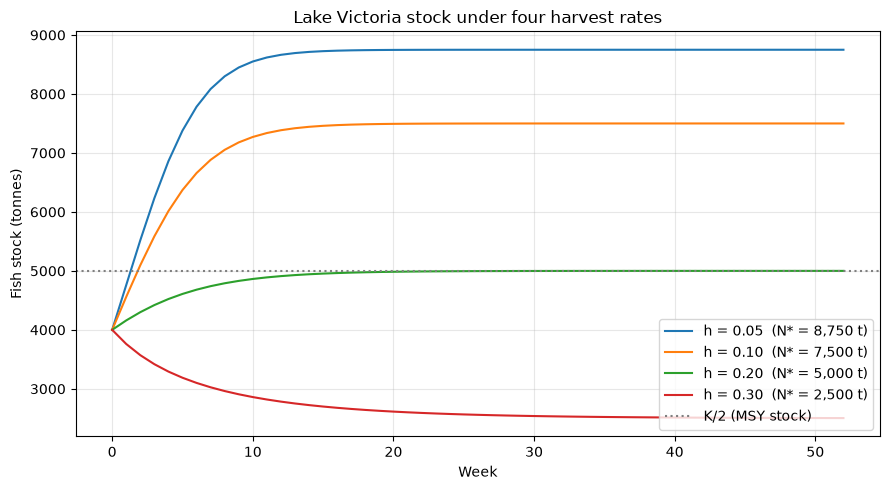

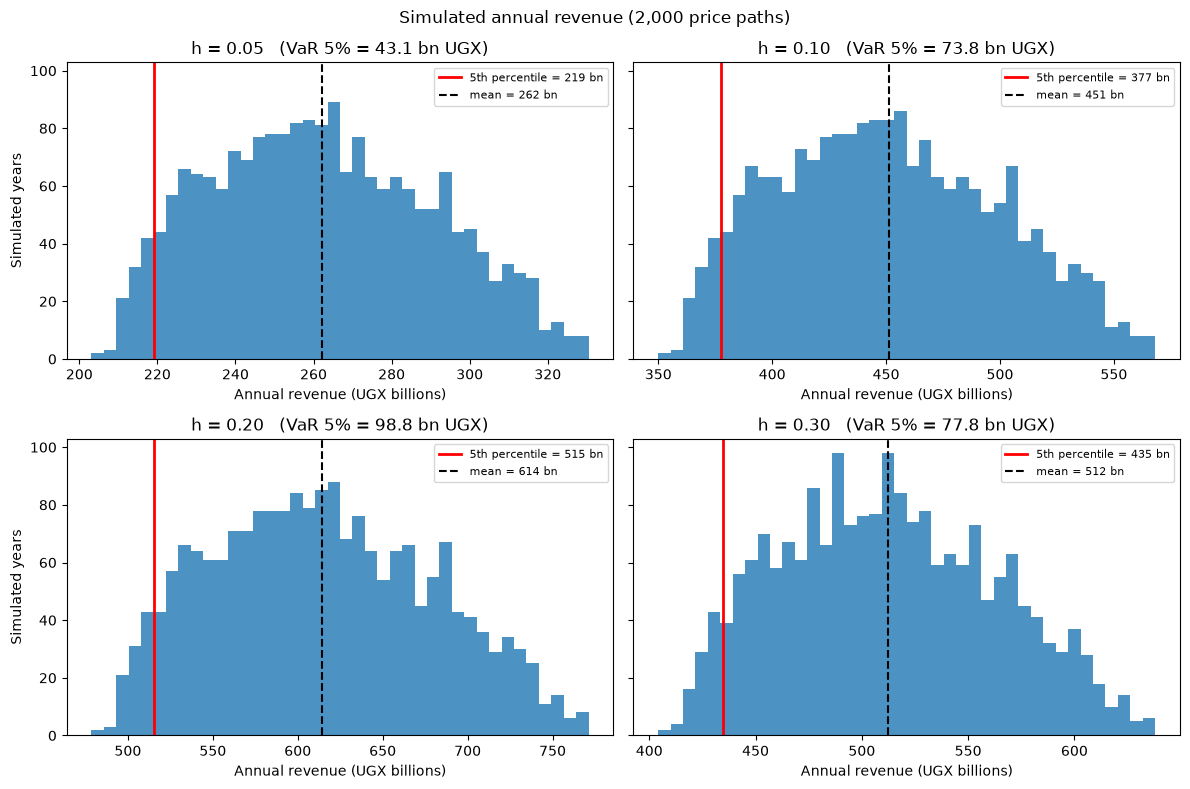

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for h in H_RATES:
    ax.plot(range(WEEKS + 1), stocks[h], label=f"h = {h:.2f}  (N* = {FishStock(h=h).equilibrium():,.0f} t)")
ax.axhline(5_000, color="grey", ls=":", label="K/2 (MSY stock)")
ax.set_xlabel("Week"); ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("Lake Victoria stock under four harvest rates"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("../figures/p3_stock.png", dpi=150); plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, h in zip(axs.ravel(), H_RATES):
    ax.hist(mc[h] / 1e9, bins=40, color="tab:blue", alpha=0.8)
    q = var[h]["quantile"] / 1e9
    ax.axvline(q, color="red", lw=2, label=f"5th percentile = {q:,.0f} bn")
    ax.axvline(var[h]["mean"] / 1e9, color="k", ls="--", label=f"mean = {var[h]['mean']/1e9:,.0f} bn")
    ax.set_title(f"h = {h:.2f}   (VaR 5% = {var[h]['var']/1e9:,.1f} bn UGX)")
    ax.set_xlabel("Annual revenue (UGX billions)"); ax.legend(fontsize=8)
axs[0, 0].set_ylabel("Simulated years"); axs[1, 0].set_ylabel("Simulated years")
fig.suptitle("Simulated annual revenue (2,000 price paths)"); fig.tight_layout()
fig.savefig("../figures/p3_revenue_hist.png", dpi=150); plt.show()

## Extension: closed season (no harvesting for 8 weeks each year), 5-year horizon
Weeks 44-51 of every year are closed. Same price paths (same seed) with and without the closure, so the comparison is paired.

,"5-yr revenue, open (UGX bn)","5-yr revenue, closed season (UGX bn)",change %,"stock yr 5, open (t)","stock yr 5, closed (t)"
h,,,,,
0.050,"1,385.103","1,177.475",-14.990,"8,750.000","9,973.943"
0.100,"2,376.112","2,040.167",-14.138,"7,500.000","9,933.530"
0.200,"3,180.820","2,844.007",-10.589,"5,000.000","9,754.418"
0.300,"2,437.494","2,510.947",3.013,"2,500.000","9,054.193"


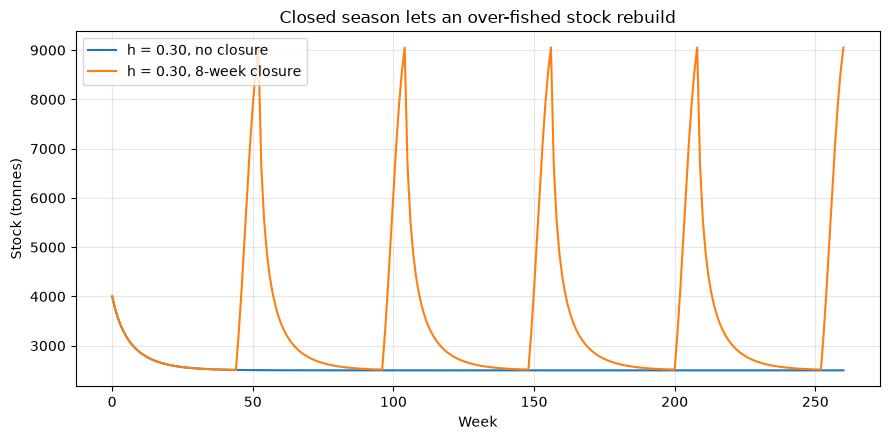

In [9]:
rows = []
for h in H_RATES:
    fs = FishStock(h=h)
    open_ = risk.monte_carlo_annual(fs, prices, 2000, weeks=260, seed=123)
    closed = risk.monte_carlo_annual(fs, prices, 2000, weeks=260, seed=123, closed_weeks=range(44, 52))
    s_open, _ = fs.simulate(260); s_closed, _ = fs.simulate(260, closed_weeks=range(44, 52))
    rows.append({"h": h, "5-yr revenue, open (UGX bn)": open_.mean() / 1e9, "5-yr revenue, closed season (UGX bn)": closed.mean() / 1e9,
                 "change %": 100 * (closed.mean() / open_.mean() - 1),
                 "stock yr 5, open (t)": s_open[-1], "stock yr 5, closed (t)": s_closed[-1]})
closure = pd.DataFrame(rows).set_index("h")
display(closure)

fig, ax = plt.subplots(figsize=(9, 4.5))
fs = FishStock(h=0.30)
ax.plot(fs.simulate(260)[0], label="h = 0.30, no closure")
ax.plot(fs.simulate(260, closed_weeks=range(44, 52))[0], label="h = 0.30, 8-week closure")
ax.set_xlabel("Week"); ax.set_ylabel("Stock (tonnes)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Closed season lets an over-fished stock rebuild"); fig.tight_layout()
fig.savefig("../figures/p3_closed_season.png", dpi=150); plt.show()

## Findings & Limitations
**Findings.** The harvest rate that maximises sustainable catch is h = r/2 = 0.20, which holds the stock at K/2 = 5,000 t and yields 1,000 t/week, exactly the theoretical MSY (rK/4). At h = 0.30 the stock settles near 2,500 t (a quarter of K), the weekly yield drops to 750 t (25 % below MSY) and 52-week revenue falls from about UGX 616 bn to 512 bn: fishing harder earns less. At h = 0.05 and 0.10 the stock stays healthy (8,750 and 7,500 t) but revenue is 57 % and 27 % lower than at MSY, so conservative harvesting trades income for a safety margin. Revenue risk looks modest in every scenario: weekly CV is 0.09-0.15 (all *Low* under my rule) and the 5 % VaR is about 15-16 % of expected annual revenue, because price is the only random input and it moves within bounds. The real risk at h = 0.30 is biological, not statistical, which is why I report a separate sustainability status. An 8-week closed season costs 11-15 % of 5-year revenue when h ≤ 0.20 but raises it by about 3 % when h = 0.30, because the pause lets the stock rebuild.

**Limitations.** The harvest is a fixed fraction of stock, so catch effort never adjusts to prices; the model is deterministic in biology (no stochastic recruitment, disease or illegal fishing) and prices are an assumed bounded random walk uncorrelated with catch. The CV bands (0.15 / 0.30) are conventions, not estimated from data, and the weekly CV mixes the early stock build-up with price noise. A year-1 horizon includes a transient from the starting stock. Parameters (r = 0.4/week, K, prices) are illustrative.